<a href="https://colab.research.google.com/github/kaczynskimat/greenlab/blob/main/analysis/data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Google Colab R

- Google is now supporting a Colab notebook with the R kernel
- We can run R codes directly on Colab
- R Colab Notebook Link: [R Google Colab](https://colab.fan/r)
    - Colab with R kernel
    - With base-R installed
    - Run R codes immediately
    - No need to setup
    - Save a copy in your Drive


## Demonstration

This notebook uses the R kernel.


In [82]:
sessionInfo()

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.4 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] jsonlite_2.0.0  lubridate_1.9.5 forcats_1.0.1   stringr_1.6.0  
 [5] purrr_1.2.2     readr_2.2.0     tidyr_1.3.2     tibble_3.3.1   
 [9] tidyverse_2.0.0 dplyr_1.2.1     ggpl

In [83]:
library(ggplot2)
library(dplyr)

In [84]:
# Install a few extra packages
required_pkgs <- c("tidyverse", "jsonlite")
new_pkgs <- required_pkgs[!(required_pkgs %in% installed.packages()[, "Package"])]
if (length(new_pkgs) > 0) install.packages(new_pkgs, quiet = TRUE)

library(tidyverse)
library(jsonlite)

In [85]:
# 1. Load the dataset
url <- "https://raw.githubusercontent.com/kaczynskimat/greenlab/main/experiment/shared-results/final/run_table.csv"
raw <- read_csv(url, show_col_types = FALSE)

cat("1. Raw Dataset Dimensions: \n", nrow(raw), "x", ncol(raw), "\n")

# 2. Filter 'done' rows
clean_runs <- raw %>%
  filter(`__done` == "DONE")
cat("Rows that have already been calculated: \n")
cat("Rows retained:", nrow(clean_runs), "out of", nrow(raw), "\n\n")

1. Raw Dataset Dimensions: 
 9600 x 16 
Rows that have already been calculated: 
Rows retained: 9592 out of 9600 



In [86]:
# 3. Check for missing values (NAs) - all columns contain the run row specification so there should be no empty rows
na_counts <- colSums(is.na(clean_runs))
cat("Missing Value (NA) Summary: \n")
print(na_counts[na_counts > 0])
if (all(na_counts == 0)) cat("No missing values found across any columns.\n\n")

# 4. Check if there are rows that have negative energy value to look for possible anomalies
energy_anomalies <- clean_runs %>%
  filter(package_energy_j <= 0 | dram_energy_j < 0)

cat("Rows with negative package energy or negative DRAM energy:", nrow(energy_anomalies), "\n\n")

Missing Value (NA) Summary: 
named numeric(0)
No missing values found across any columns.

Rows with negative package energy or negative DRAM energy: 0 



In [87]:
# 5. Extract repetition and iteration number and variant of the code (original or modified)
clean_runs <- clean_runs %>%
  mutate(
    repetition = as.integer(str_extract(`__run_id`, "(?<=repetition_)\\d+")),
    run_seq    = as.integer(str_extract(`__run_id`, "(?<=run_)\\d+")),
    variant    = as.character(variant)
  )

  # Code for ensuring that they tested the same input (there is only one seed and hash per pair)
  workload_mismatches <- clean_runs %>%
  group_by(problem, variant, repetition) %>%
  summarise(
    n_treatments = n_distinct(treatment),
    n_seeds      = n_distinct(workload_seed),
    n_hashes     = n_distinct(workload_sha256),
    .groups = "drop"
  ) %>%
  filter(n_treatments == 2 & (n_seeds > 1 | n_hashes > 1))

cat("Number of (problem, variant, repetition) pairs with mismatched seed/hash:", nrow(workload_mismatches), "\n\n")

Number of (problem, variant, repetition) pairs with mismatched seed/hash: 0 



In [88]:
# 7. Check how many times a snippet has been measured (problem x variant x treatment)
snippet_counts <- clean_runs %>%
  count(problem, variant, treatment, name = "repetitions")

cat("--- 6. Repetitions per Snippet (Summary) ---\n")
cat("Total distinct snippets found:", nrow(snippet_counts), "(expected: 96)\n")
cat("Min repetitions:", min(snippet_counts$repetitions), "\n")
cat("Median repetitions:", median(snippet_counts$repetitions), "\n")
cat("Mean repetitions:", round(mean(snippet_counts$repetitions), 1), "\n")
cat("Max repetitions:", max(snippet_counts$repetitions), "\n\n")

# Display a preview of snippet counts
head(snippet_counts, 10)

--- 6. Repetitions per Snippet (Summary) ---
Total distinct snippets found: 96 (expected: 96)
Min repetitions: 92 
Median repetitions: 100 
Mean repetitions: 99.9 
Max repetitions: 100 



problem,variant,treatment,repetitions
<dbl>,<chr>,<chr>,<int>
3,1,modified,100
3,1,original,100
3,2,modified,100
3,2,original,100
3,3,modified,100
3,3,original,100
15,1,modified,100
15,1,original,100
15,2,modified,100


In [89]:
library(tidyverse)

# Lookup table to match the problem id to the problem name, difficulty class, guideline id and family
metadata <- tribble(
  ~problem, ~name,                                            ~difficulty, ~guideline_id, ~guideline_family,
       387, "First Unique Character in a String",             "easy",      "G1",          "Code Optimization",
         3, "Longest Substring Without Repeating Characters", "medium",    "G1",          "Code Optimization",
       977, "Squares of a Sorted Array",                      "easy",      "G2",          "Code Optimization",
       240, "Search a 2D Matrix II",                          "medium",    "G2",          "Code Optimization",
       605, "Can Place Flowers",                              "easy",      "G3",          "Code Optimization",
        15, "3Sum",                                           "medium",    "G3",          "Code Optimization",
       383, "Ransom Note",                                    "easy",      "G6",          "Code Optimization",
       442, "Find All Duplicates in an Array",                "medium",    "G6",          "Code Optimization",
       509, "Fibonacci Number",                               "easy",      "G18",         "Function Calls",
       322, "Coin Change",                                    "medium",    "G18",         "Function Calls",
       125, "Valid Palindrome",                               "easy",      "G19",         "Function Calls",
       200, "Number of Islands",                              "medium",    "G19",         "Function Calls",
       867, "Transpose Matrix",                               "easy",      "G24",         "Other",
       238, "Product of Array Except Self",                   "medium",    "G24",         "Other",
       905, "Sort Array By Parity",                           "easy",      "G27",         "Other",
        49, "Group Anagrams",                                 "medium",    "G27",         "Other"
)


In [90]:
# Compute Total Energy E and Power P
runs_with_metrics <- clean_runs %>%
  mutate(
    problem        = as.integer(problem), # convert the problem id to integer so that it matches the data type in our metadata table
    variant        = as.character(variant),
    total_energy_j = package_energy_j + dram_energy_j, # calculcate total energy
    total_power_w  = total_energy_j / measurement_duration_seconds # calculate total power in watt
  )

In [91]:
snippet_table <- runs_with_metrics %>%
  # Group the data from run_table.csv (containing 9600 rows) into 96 rows (for every combination of problem (e.g. problem p977), variant (e.g. 3rd variant), treatment(modified vs original))
  group_by(problem, variant, treatment) %>%
  summarise(
    n_repetitions         = n(),
    # compute the median and mean across all the metrics
    # mean part
    energy_total_median   = median(total_energy_j),
    energy_pkg_median     = median(package_energy_j),
    runtime_median        = median(benchmark_runtime_seconds),
    power_median          = median(total_power_w),
    cpu_median            = median(avg_cpu_usage_percent),
    rss_median            = median(avg_rss_bytes),
    # median part
    energy_total_mean     = mean(total_energy_j),
    energy_pkg_mean       = mean(package_energy_j),
    runtime_mean          = mean(benchmark_runtime_seconds),
    power_mean            = mean(total_power_w),
    cpu_mean              = mean(avg_cpu_usage_percent),
    rss_mean              = mean(avg_rss_bytes),
    .groups = "drop"
  ) %>%
    # join the table with the metadata table to have all the problem descriptions
  left_join(metadata, by = "problem")

cat("Rows (snippets):", nrow(snippet_table), "(expected: 96 when complete)\n\n")


Rows (snippets): 96 (expected: 96 when complete)



In [92]:
# separate the 2 types of treatments (original and modified) to create an inner join in order to compare the deltas from our experiment planning part
orig <- snippet_table %>%
  filter(treatment == "original") %>%
  select(problem, variant, name, difficulty, guideline_id, guideline_family,
         n_reps_orig = n_repetitions,
         starts_with("energy_"), starts_with("runtime_"),
         starts_with("power_"), starts_with("cpu_"), starts_with("rss_"))
mod <- snippet_table %>%
  filter(treatment == "modified") %>%
  select(problem, variant,
         n_reps_mod = n_repetitions,
         starts_with("energy_"), starts_with("runtime_"),
         starts_with("power_"), starts_with("cpu_"), starts_with("rss_"))

# create 48 matched pairs
pair_table <- inner_join(orig, mod, by = c("problem", "variant"), suffix = c("_orig", "_mod")) %>%
  mutate(
    # Compute absolute (dE in J) and relative savings (dX_rel) for energy, time, power, CPU, and RAM
    dE          = energy_total_median_orig - energy_total_median_mod,
    dE_rel      = (energy_total_median_orig - energy_total_median_mod) / energy_total_median_orig,

    # Runtime, Power, CPU, Memory relative deltas
    dT_rel      = (runtime_median_orig - runtime_median_mod) / runtime_median_orig,
    dP_rel      = (power_median_orig - power_median_mod) / power_median_orig,
    dCPU_rel    = (cpu_median_orig - cpu_median_mod) / cpu_median_orig,
    dMem_rel    = (rss_median_orig - rss_median_mod) / rss_median_orig,
  )


In [93]:
# export summary tables to CSV
write_csv(snippet_table, "snippet_summary.csv")
write_csv(pair_table, "paired_deltas.csv")

cat("Rows (pairs):", nrow(pair_table), "(expected: 48 when complete)\n")
cat("Files saved: 'snippet_summary.csv' and 'paired_deltas.csv'\n\n")

# Preview of 10 elements in the table
pair_table %>%
  select(problem, variant, guideline_id, difficulty, dE, dE_rel, dT_rel, dP_rel, dMem_rel) %>%
  head(10) %>%
  print()

Rows (pairs): 48 (expected: 48 when complete)
Files saved: 'snippet_summary.csv' and 'paired_deltas.csv'

# A tibble: 10 × 9
   problem variant guideline_id difficulty    dE  dE_rel    dT_rel    dP_rel
     <dbl> <chr>   <chr>        <chr>      <dbl>   <dbl>     <dbl>     <dbl>
 1       3 1       G1           medium      55.4  0.0766  0.0732    0.00848 
 2       3 2       G1           medium     -28.6 -0.0423 -0.0321    0.000382
 3       3 3       G1           medium     -29.2 -0.0444  0.0111   -0.000771
 4      15 1       G3           medium     -20.4 -0.0286  0.00209   0.00162 
 5      15 2       G3           medium      23.9  0.0328  0.000249  0.00522 
 6      15 3       G3           medium     -17.8 -0.0253  0.00330   0.00105 
 7      49 1       G27          medium     -89.6 -0.132  -0.0783   -0.00534 
 8      49 2       G27          medium     -51.7 -0.0712 -0.0751   -0.00154 
 9      49 3       G27          medium     -35.7 -0.0491 -0.104     0.00467 
10     125 1       G19      

In [94]:
library(tidyverse)
# Create a figures folder
dir.create("figures", showWarnings = FALSE)

# Convert deltas to percentages for clearer plotting and reporting
pair_plot <- pair_table %>%
  mutate(
    dE_pct   = dE_rel * 100,
    dT_pct   = dT_rel * 100,
    dP_pct   = dP_rel * 100,
    dCPU_pct = dCPU_rel * 100,
    dMem_pct = dMem_rel * 100,
    # sort data in levels to avoid the data being sorted alphabetically (G1, G18, G19, G2, etc.)
    guideline_id = factor(guideline_id, levels = c("G1", "G2", "G3", "G6", "G18", "G19", "G24", "G27")),
    guideline_family = factor(guideline_family, levels = c("Code Optimization", "Function Calls", "Other")),
    difficulty = factor(difficulty, levels = c("easy", "medium"))
  )

# ------------------------------------------------------------------------------
# 1. Summary Statistics Tables (Mean, Median, SD, IQR, Min, Max, N)
# ------------------------------------------------------------------------------

# Overall summary across all 48 pairs
summary_overall <- pair_plot %>%
  summarise(
    Metric   = "Total Energy Savings (dE%)",
    N_pairs  = n(),
    Mean     = mean(dE_pct, na.rm = TRUE),
    SD       = sd(dE_pct, na.rm = TRUE),
    Median   = median(dE_pct, na.rm = TRUE),
    IQR      = IQR(dE_pct, na.rm = TRUE),
    Min      = min(dE_pct, na.rm = TRUE),
    Max      = max(dE_pct, na.rm = TRUE)
  )

# Grouped by Guideline (6 pairs each)
summary_guideline <- pair_plot %>%
  group_by(guideline_family, guideline_id) %>%
  summarise(
    N_pairs = n(),
    Mean    = mean(dE_pct, na.rm = TRUE),
    SD      = sd(dE_pct, na.rm = TRUE),
    Median  = median(dE_pct, na.rm = TRUE),
    IQR     = IQR(dE_pct, na.rm = TRUE),
    Min     = min(dE_pct, na.rm = TRUE),
    Max     = max(dE_pct, na.rm = TRUE),
    .groups = "drop"
  )

# Grouped by Family (24 / 12 / 12 pairs)
summary_family <- pair_plot %>%
  group_by(guideline_family) %>%
  summarise(
    N_pairs = n(),
    Mean    = mean(dE_pct, na.rm = TRUE),
    SD      = sd(dE_pct, na.rm = TRUE),
    Median  = median(dE_pct, na.rm = TRUE),
    IQR     = IQR(dE_pct, na.rm = TRUE),
    Min     = min(dE_pct, na.rm = TRUE),
    Max     = max(dE_pct, na.rm = TRUE),
    .groups = "drop"
  )

# Grouped by Difficulty (24 Easy / 24 Medium)
summary_difficulty <- pair_plot %>%
  group_by(difficulty) %>%
  summarise(
    N_pairs = n(),
    Mean    = mean(dE_pct, na.rm = TRUE),
    SD      = sd(dE_pct, na.rm = TRUE),
    Median  = median(dE_pct, na.rm = TRUE),
    IQR     = IQR(dE_pct, na.rm = TRUE),
    Min     = min(dE_pct, na.rm = TRUE),
    Max     = max(dE_pct, na.rm = TRUE),
    .groups = "drop"
  )

# Export summary CSVs
write_csv(summary_overall, "summary_overall.csv")
write_csv(summary_guideline, "summary_by_guideline.csv")
write_csv(summary_family, "summary_by_family.csv")
write_csv(summary_difficulty, "summary_by_difficulty.csv")

cat("--- Summary Tables Exported ---\n\n")
cat("Overall dE%:\n")
print(summary_overall)
cat("\nBy Guideline dE%:\n")
print(summary_guideline)

--- Summary Tables Exported ---

Overall dE%:
# A tibble: 1 × 8
  Metric                     N_pairs  Mean    SD Median   IQR   Min   Max
  <chr>                        <int> <dbl> <dbl>  <dbl> <dbl> <dbl> <dbl>
1 Total Energy Savings (dE%)      48 -2.49  54.5   2.04  14.2 -190.  93.8

By Guideline dE%:
# A tibble: 8 × 9
  guideline_family  guideline_id N_pairs   Mean    SD Median    IQR      Min
  <fct>             <fct>          <int>  <dbl> <dbl>  <dbl>  <dbl>    <dbl>
1 Code Optimization G1                 6   3.71  7.14   4.77  11.1    -4.44 
2 Code Optimization G2                 6   3.35  4.04   3.32   3.94   -0.925
3 Code Optimization G3                 6   2.21  4.21   2.71   7.04   -2.86 
4 Code Optimization G6                 6  14.9  12.7   16.8   13.0    -3.93 
5 Function Calls    G18                6  58.9  48.0   87.3   69.2    -6.02 
6 Function Calls    G19                6   8.15  7.26   7.50   7.61    0.225
7 Other             G24                6 -99.2  93.9  -97.7  

In [98]:

# 2. QQ plot for RQ1
p_qq <- ggplot(pair_table, aes(sample = dE)) +
  stat_qq(color = "steelblue", size = 2) +
  stat_qq_line(color = "red", linewidth = 1.5) +
  theme_bw(base_size = 12) +
  labs(
    title = "Q-Q Plot: Paired Energy Differences (dE)",
    x = "Theoretical Quantiles",
    y = "Sample Quantiles"
  )

ggsave("figures/qq_plot_dE.png", p_qq, width = 6, height = 4.5, dpi = 300)

# 3. RQ1 Plot: Distributions of dE%, dT%, and dP% across all 48 pairs
rq1_long <- pair_plot %>%
  select(problem, variant, dE_pct, dT_pct, dP_pct) %>%
  pivot_longer(cols = c(dE_pct, dT_pct, dP_pct), names_to = "Metric", values_to = "PercentChange") %>%
  mutate(Metric = recode(Metric,
    "dE_pct" = "Energy (dE%)",
    "dT_pct" = "Runtime (dT%)",
    "dP_pct" = "Power (dP%)"
  ))

p_rq1 <- ggplot(rq1_long, aes(x = Metric, y = PercentChange, fill = Metric)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray40") +
  geom_boxplot(width = 0.45, alpha = 0.7, outlier.shape = 21, outlier.size = 2) +
  geom_jitter(width = 0.12, alpha = 0.4, size = 1.5) +
  theme_bw(base_size = 12) +
  theme(legend.position = "none") +
  labs(
    title = "RQ1: Relative Savings across 48 Code Pairs",
    subtitle = "Positive % = savings; Negative % = regression",
    x = "",
    y = "Relative Change (%)"
  )
ggsave("figures/rq1_metric_distributions.png", p_rq1, width = 6, height = 4.5, dpi = 300)






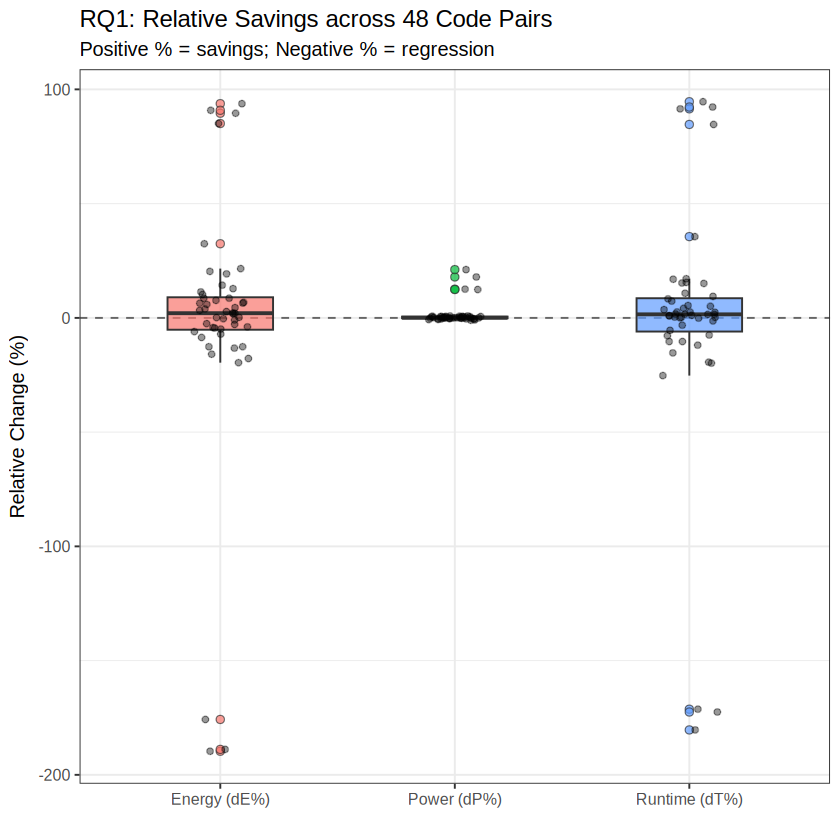

In [99]:
print(p_rq1)

In [100]:
# 4. RQ2 Plot: Energy Savings (dE%) by Guideline, Family, and Difficulty
p_rq2_guidelines <- ggplot(pair_plot, aes(x = guideline_id, y = dE_pct, fill = guideline_family)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray40") +
  geom_boxplot(alpha = 0.7, outlier.shape = 21, width = 0.5) +
  geom_jitter(width = 0.15, alpha = 0.5, size = 1.5) +
  theme_bw(base_size = 12) +
  labs(
    title = "RQ2a: Energy Savings (dE%) by Guideline",
    subtitle = "Each guideline evaluated on 6 snippet pairs (3 Easy, 3 Medium)",
    x = "Guideline ID",
    y = "Energy Savings dE (%)",
    fill = "Family"
  )
ggsave("figures/rq2_energy_by_guideline.png", p_rq2_guidelines, width = 8, height = 4.5, dpi = 300)

p_rq2_difficulty <- ggplot(pair_plot, aes(x = difficulty, y = dE_pct, fill = difficulty)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray40") +
  geom_boxplot(alpha = 0.7, width = 0.42, outlier.shape = 21) +
  geom_jitter(width = 0.12, alpha = 0.5, size = 1.6) +
  theme_bw(base_size = 12) +
  theme(legend.position = "none") +
  labs(
    title = "RQ2c: Energy Savings (dE%) by Problem Difficulty",
    x = "Difficulty Level",
    y = "Energy Savings dE (%)"
  )
ggsave("figures/rq2_energy_by_difficulty.png", p_rq2_difficulty, width = 5, height = 4.5, dpi = 300)

# 5. RQ3 Plot: Scatter plots of Resource Trade-offs (CPU & Memory vs Energy)
p_rq3_mem <- ggplot(pair_plot, aes(x = dMem_pct, y = dE_pct)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray50") +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray50") +
  geom_point(aes(color = guideline_family), size = 2.5, alpha = 0.8) +
  geom_smooth(method = "lm", se = FALSE, color = "black", linetype = "dotted", linewidth = 0.8) +
  theme_bw(base_size = 12) +
  labs(
    title = "RQ3b: Memory Savings vs. Energy Savings",
    x = "Memory Savings dMem (%)",
    y = "Energy Savings dE (%)",
    color = "Guideline Family"
  )
ggsave("figures/rq3_scatter_memory_vs_energy.png", p_rq3_mem, width = 6.5, height = 4.5, dpi = 300)

p_rq3_cpu <- ggplot(pair_plot, aes(x = dCPU_pct, y = dE_pct)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray50") +
  geom_vline(xintercept = 0, linetype = "dashed", color = "gray50") +
  geom_point(aes(color = guideline_family), size = 2.5, alpha = 0.8) +
  geom_smooth(method = "lm", se = FALSE, color = "black", linetype = "dotted", linewidth = 0.8) +
  theme_bw(base_size = 12) +
  labs(
    title = "RQ3b: CPU Usage Change vs. Energy Savings",
    x = "CPU Change dCPU (%)",
    y = "Energy Savings dE (%)",
    color = "Guideline Family"
  )
ggsave("figures/rq3_scatter_cpu_vs_energy.png", p_rq3_cpu, width = 6.5, height = 4.5, dpi = 300)

cat("--- All Figures Saved to 'figures/' Folder ---\n")

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


--- All Figures Saved to 'figures/' Folder ---


In [101]:
# Statistical testing

library(tidyverse)

# Helper function for Cliff's delta (non-parametric effect size)
calc_cliffs_delta <- function(x, y) {
  comp <- outer(x, y, function(a, b) sign(a - b))
  delta <- mean(comp)
  mag <- cut(abs(delta),
             breaks = c(-Inf, 0.147, 0.33, 0.474, Inf),
             labels = c("negligible", "small", "medium", "large"))
  return(list(estimate = delta, magnitude = as.character(mag)))
}

# Helper function for Cohen's d
calc_cohens_d <- function(d) {
  d_val <- mean(d, na.rm = TRUE) / sd(d, na.rm = TRUE)
  mag <- cut(abs(d_val),
             breaks = c(-Inf, 0.2, 0.5, 0.8, Inf),
             labels = c("negligible", "small", "medium", "large"))
  return(list(estimate = d_val, magnitude = as.character(mag)))
}

# Collect all primary tests for multiple testing correction
results_table <- tibble()

# RQ1 / H01: Paired Absolute Energy Change (dE across 48 pairs)
cat("RQ1 / H01: PAIRED ABSOLUTE ENERGY CHANGE (dE = E_orig - E_mod)\n")

# 1. Normality check
shapiro_h01 <- shapiro.test(pair_table$dE)
cat("Shapiro-Wilk normality on dE: W =", round(shapiro_h01$statistic, 4),
    ", p-value =", format.pval(shapiro_h01$p.value, eps = 0.001), "\n")

# Non-parametric Wilcoxon signed-rank test
test_h01 <- wilcox.test(pair_table$dE, mu = 0, exact = FALSE, conf.int = TRUE)
cld_h01  <- calc_cliffs_delta(pair_table$dE, rep(0, length(pair_table$dE)))

cat("Wilcoxon signed-rank test on paired differences:\n")
cat("  V =", round(test_h01$statistic, 2), ", p-value =", format.pval(test_h01$p.value, eps = 0.001), "\n")
cat("  Cliff's delta =", round(cld_h01$estimate, 3), "(", cld_h01$magnitude, ")\n\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H01 (Overall dE != 0)",
  Test_Name = "Wilcoxon signed-rank",
  Statistic = as.numeric(test_h01$statistic),
  p_raw = test_h01$p.value,
  Effect_Metric = "Cliff's delta",
  Effect_Size = cld_h01$estimate,
  Magnitude = cld_h01$magnitude
))

# RQ2: Group Comparisons
cat("RQ2: GROUP COMPARISONS ON RELATIVE ENERGY SAVINGS (dE_rel)\n")

# H02a: Between the 8 Guidelines (6 pairs each)
cat("--- H02a: Between 8 Guidelines ---\n")
kw_g <- kruskal.test(dE_rel ~ guideline_id, data = pair_table)
eps_sq_g <- (kw_g$statistic - 8 + 1) / (48 - 8)
cat("Kruskal-Wallis across 8 Guidelines: chi-sq =", round(kw_g$statistic, 3),
    ", df =", kw_g$parameter, ", p =", format.pval(kw_g$p.value, eps = 0.001), "\n")
cat("Epsilon-squared (effect size) =", round(eps_sq_g, 3), "\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H02a (Across 8 Guidelines)",
  Test_Name = "Kruskal-Wallis",
  Statistic = as.numeric(kw_g$statistic),
  p_raw = kw_g$p.value,
  Effect_Metric = "Epsilon-squared",
  Effect_Size = as.numeric(eps_sq_g),
  Magnitude = ifelse(eps_sq_g > 0.14, "large", ifelse(eps_sq_g > 0.06, "medium", "small"))
))

# Pairwise post-hoc with Benjamini-Hochberg adjustment
cat("\nPost-hoc pairwise Wilcoxon between Guidelines (p.adj < 0.05):\n")
pw_g <- pairwise.wilcox.test(pair_table$dE_rel, pair_table$guideline_id, p.adjust.method = "BH", exact = FALSE)
pw_g_df <- as.data.frame(as.table(pw_g$p.value)) %>% filter(!is.na(Freq)) %>% filter(Freq < 0.05)
if (nrow(pw_g_df) > 0) {
  print(pw_g_df)
} else {
  cat("  No specific pair reached significance at FDR < 0.05.\n")
}

# H02b: Between 3 Families (24 Code Opt, 12 Function Calls, 12 Other)
cat("\n--- H02b: Between 3 Guideline Families ---\n")
kw_fam <- kruskal.test(dE_rel ~ guideline_family, data = pair_table)
eps_sq_fam <- (kw_fam$statistic - 3 + 1) / (48 - 3)
cat("Kruskal-Wallis across 3 Families: chi-sq =", round(kw_fam$statistic, 3),
    ", df =", kw_fam$parameter, ", p =", format.pval(kw_fam$p.value, eps = 0.001), "\n")
cat("Epsilon-squared =", round(eps_sq_fam, 3), "\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H02b (Across 3 Families)",
  Test_Name = "Kruskal-Wallis",
  Statistic = as.numeric(kw_fam$statistic),
  p_raw = kw_fam$p.value,
  Effect_Metric = "Epsilon-squared",
  Effect_Size = as.numeric(eps_sq_fam),
  Magnitude = ifelse(eps_sq_fam > 0.14, "large", ifelse(eps_sq_fam > 0.06, "medium", "small"))
))

cat("\nPost-hoc pairwise Wilcoxon between Families (BH-adjusted):\n")
pw_fam <- pairwise.wilcox.test(pair_table$dE_rel, pair_table$guideline_family, p.adjust.method = "BH", exact = FALSE)
print(round(pw_fam$p.value, 4))

# H02c: Easy vs. Medium (24 pairs each)
cat("\n--- H02c: Easy vs. Medium Problems ---\n")
test_diff <- wilcox.test(dE_rel ~ difficulty, data = pair_table, exact = FALSE)
easy_vals <- pair_table %>% filter(difficulty == "easy") %>% pull(dE_rel)
med_vals  <- pair_table %>% filter(difficulty == "medium") %>% pull(dE_rel)
cld_diff  <- calc_cliffs_delta(easy_vals, med_vals)

cat("Mann-Whitney U (Wilcoxon Rank-Sum): W =", test_diff$statistic,
    ", p =", format.pval(test_diff$p.value, eps = 0.001), "\n")
cat("Cliff's delta =", round(cld_diff$estimate, 3), "(", cld_diff$magnitude, ")\n\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H02c (Easy vs Medium)",
  Test_Name = "Wilcoxon rank-sum",
  Statistic = as.numeric(test_diff$statistic),
  p_raw = test_diff$p.value,
  Effect_Metric = "Cliff's delta",
  Effect_Size = cld_diff$estimate,
  Magnitude = cld_diff$magnitude
))

# RQ3: Resource Trade-offs (CPU & Memory)
cat("RQ3: CPU & MEMORY IMPACTS AND CORRELATIONS\n")

# H03a1: Memory relative change != 0
test_mem <- wilcox.test(pair_table$dMem_rel, mu = 0, exact = FALSE)
cld_mem  <- calc_cliffs_delta(pair_table$dMem_rel, rep(0, nrow(pair_table)))
cat("H03a (Memory Change dMem_rel != 0): V =", test_mem$statistic,
    ", p =", format.pval(test_mem$p.value, eps = 0.001),
    ", Cliff's delta =", round(cld_mem$estimate, 3), "\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H03a (Memory Change != 0)",
  Test_Name = "Wilcoxon signed-rank",
  Statistic = as.numeric(test_mem$statistic),
  p_raw = test_mem$p.value,
  Effect_Metric = "Cliff's delta",
  Effect_Size = cld_mem$estimate,
  Magnitude = cld_mem$magnitude
))

# H03a2: CPU relative change != 0
test_cpu <- wilcox.test(pair_table$dCPU_rel, mu = 0, exact = FALSE)
cld_cpu  <- calc_cliffs_delta(pair_table$dCPU_rel, rep(0, nrow(pair_table)))
cat("H03a (CPU Change dCPU_rel != 0): V =", test_cpu$statistic,
    ", p =", format.pval(test_cpu$p.value, eps = 0.001),
    ", Cliff's delta =", round(cld_cpu$estimate, 3), "\n\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H03a (CPU Change != 0)",
  Test_Name = "Wilcoxon signed-rank",
  Statistic = as.numeric(test_cpu$statistic),
  p_raw = test_cpu$p.value,
  Effect_Metric = "Cliff's delta",
  Effect_Size = cld_cpu$estimate,
  Magnitude = cld_cpu$magnitude
))

# H03b: Spearman rank correlations with energy savings (dE_rel)
cor_mem <- cor.test(pair_table$dE_rel, pair_table$dMem_rel, method = "spearman", exact = FALSE)
cat("H03b (Correlation dE_rel vs dMem_rel): rho =", round(cor_mem$estimate, 3),
    ", p =", format.pval(cor_mem$p.value, eps = 0.001), "\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H03b (Correlation dE ~ dMem)",
  Test_Name = "Spearman correlation",
  Statistic = as.numeric(cor_mem$estimate),
  p_raw = cor_mem$p.value,
  Effect_Metric = "Spearman rho",
  Effect_Size = as.numeric(cor_mem$estimate),
  Magnitude = ifelse(abs(cor_mem$estimate) > 0.5, "large", ifelse(abs(cor_mem$estimate) > 0.3, "medium", "small"))
))

cor_cpu <- cor.test(pair_table$dE_rel, pair_table$dCPU_rel, method = "spearman", exact = FALSE)
cat("H03b (Correlation dE_rel vs dCPU_rel): rho =", round(cor_cpu$estimate, 3),
    ", p =", format.pval(cor_cpu$p.value, eps = 0.001), "\n\n")

results_table <- bind_rows(results_table, tibble(
  Hypothesis = "H03b (Correlation dE ~ dCPU)",
  Test_Name = "Spearman correlation",
  Statistic = as.numeric(cor_cpu$estimate),
  p_raw = cor_cpu$p.value,
  Effect_Metric = "Spearman rho",
  Effect_Size = as.numeric(cor_cpu$estimate),
  Magnitude = ifelse(abs(cor_cpu$estimate) > 0.5, "large", ifelse(abs(cor_cpu$estimate) > 0.3, "medium", "small"))
))

# Multiple Testing Correction (Benjamini-Hochberg)
results_table <- results_table %>%
  mutate(
    p_adjusted_BH = p.adjust(p_raw, method = "BH"),
    Significant_FDR_05 = ifelse(p_adjusted_BH < 0.05, "YES", "NO")
  )

write_csv(results_table, "statistical_test_results.csv")

cat("FINAL STATISTICAL RESULTS TABLE (BENJAMINI-HOCHBERG ADJUSTED)\n")
print(results_table %>% select(Hypothesis, Test_Name, p_raw, p_adjusted_BH, Significant_FDR_05, Effect_Metric, Effect_Size, Magnitude))


RQ1 / H01: PAIRED ABSOLUTE ENERGY CHANGE (dE = E_orig - E_mod)
Shapiro-Wilk normality on dE: W = 0.5986 , p-value = < 0.001 
Wilcoxon signed-rank test on paired differences:
  V = 683 , p-value = 0.33242 
  Cliff's delta = 0.167 ( small )

RQ2: GROUP COMPARISONS ON RELATIVE ENERGY SAVINGS (dE_rel)
--- H02a: Between 8 Guidelines ---
Kruskal-Wallis across 8 Guidelines: chi-sq = 30.099 , df = 7 , p = < 0.001 
Epsilon-squared (effect size) = 0.577 

Post-hoc pairwise Wilcoxon between Guidelines (p.adj < 0.05):
   Var1 Var2       Freq
1   G24   G1 0.01291785
2   G27   G1 0.01291785
3   G24  G18 0.01291785
4   G27  G18 0.01922438
5   G24  G19 0.01291785
6   G27  G19 0.01291785
7   G24   G2 0.01291785
8   G27   G2 0.01291785
9    G3  G24 0.01291785
10   G6  G24 0.01291785
11   G3  G27 0.01291785
12   G6  G27 0.01291785

--- H02b: Between 3 Guideline Families ---
Kruskal-Wallis across 3 Families: chi-sq = 27.515 , df = 2 , p = < 0.001 
Epsilon-squared = 0.567 

Post-hoc pairwise Wilcoxon betwe